Total shipments: 240
Total shipping cost: $ 387161.52
Average cost per shipment: $ 1613.17
On-time delivery rate: 75.0 %


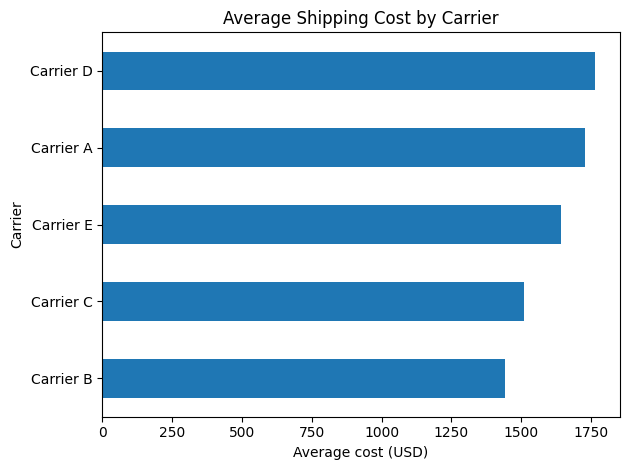

In [ ]:

import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("shipments.csv")

print("Total shipments:", len(df))
print("Total shipping cost: $", round(df["Shipping_Cost_USD"].sum(), 2))
print("Average cost per shipment: $", round(df["Shipping_Cost_USD"].mean(), 2))
print("On-time delivery rate:",
      round((df["On_Time"] == "Yes").mean() * 100, 1), "%")

carrier_cost = df.groupby("Carrier")["Shipping_Cost_USD"].mean().sort_values()

carrier_cost.plot(kind="barh")
plt.title("Average Shipping Cost by Carrier")
plt.xlabel("Average cost (USD)")
plt.tight_layout()
plt.show()

,Shipments,Average_Cost,On_Time_Rate
Carrier,,,
Carrier D,44,1765.25,72.73
Carrier A,49,1728.27,77.55
Carrier E,44,1642.26,77.27
Carrier C,60,1508.61,78.33
Carrier B,43,1442.54,67.44


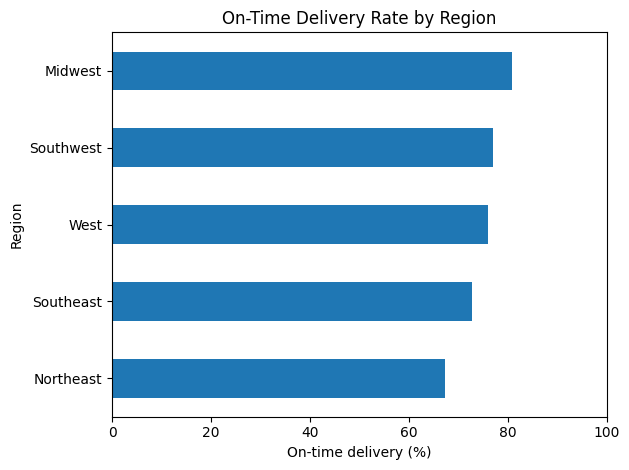

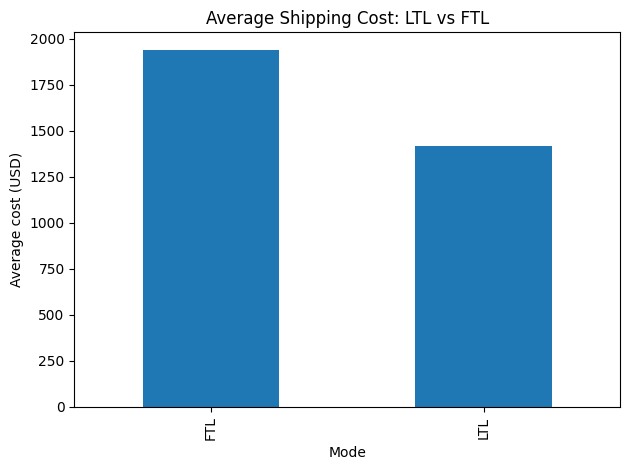

In [ ]:

# Carrier performance summary
carrier_summary = df.groupby("Carrier").agg(
    Shipments=("Shipment_ID", "count"),
    Average_Cost=("Shipping_Cost_USD", "mean"),
    On_Time_Rate=("On_Time", lambda x: (x == "Yes").mean() * 100)
).round(2)

display(carrier_summary.sort_values("Average_Cost", ascending=False))

# Chart 1: On-time delivery by region
region_performance = df.groupby("Region").agg(
    On_Time_Rate=("On_Time", lambda x: (x == "Yes").mean() * 100)
)

region_performance["On_Time_Rate"].sort_values().plot(
    kind="barh", title="On-Time Delivery Rate by Region"
)
plt.xlabel("On-time delivery (%)")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

# Chart 2: Shipping costs by shipment mode
df.groupby("Mode")["Shipping_Cost_USD"].mean().plot(
    kind="bar", title="Average Shipping Cost: LTL vs FTL"
)
plt.ylabel("Average cost (USD)")
plt.tight_layout()
plt.show()
